# 09 — Renkli Görüntülerden Özellik Çıkarma (300 × 225)
Bu çalışma **grayscale HOG yerine doğrudan orijinal renkli görüntüleri** kullanır. HSV renk histogramları, bölgesel renk histogramları, renk ortalama/standart sapmaları ve lezyon alan oranını çıkarır. Original ve Masked sürümleri vardır.

**Not:** Renkli özellikler 439 boyutludur; bu ilk deneyde HOG ile birleştirmiyoruz. Masked deneyinde gerçek segmentasyon maskeleri kullanılır.

## 1. Proje ve veri yolları

In [ ]:
from pathlib import Path
import sys
import numpy as np

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import BASE_DIR
from src.data_loader import load_dataset

FEATURE_DIR = BASE_DIR / "outputs" / "features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
print("Proje:", BASE_DIR)


df = load_dataset(require_masks=True).reset_index(drop=True)
assert df["image"].is_unique
print("Toplam görüntü:",len(df))
print(df["label"].value_counts())

Proje: C:\Users\Deniz TOZAN\OneDrive - Analythinx Bilişim Hizmetleri Ticaret Anonim Şirketi\WORK\Calismalar\uygulama\Kodlar\Health
Toplam görüntü: 10015
label
NV       6705
MEL      1113
BKL      1099
BCC       514
AKIEC     327
VASC      142
DF        115
Name: count, dtype: int64


## 2. Renk özellik çıkarım fonksiyonu

In [2]:
import cv2
from src.preprocessing import read_image

SIZE = (300, 225)    # OpenCV (width, height)
N_BINS = 16          # HSV global histogram bins per channel
GRID = (4, 4)       # Spatial histogram blocks
GRID_BINS = 8       # histogram bins per channel within each block

def rgb_color_features(image_path, mask_path=None):
    """RGB image -> HSV global+spatial histograms and HSV moments.

    If a mask is provided, use only lesion pixels; background contributes nothing.
    Returned features are fixed length, float32.
    """
    bgr = read_image(image_path)
    bgr = cv2.resize(bgr, SIZE, interpolation=cv2.INTER_AREA)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)

    if mask_path is None:
        mask = np.ones(hsv.shape[:2], dtype=bool)
    else:
        raw_mask = read_image(mask_path, grayscale=True)
        raw_mask = cv2.resize(raw_mask, SIZE, interpolation=cv2.INTER_NEAREST)
        mask = raw_mask > 127

    features = []
    # HSV has H in [0,180], S/V in [0,256)
    for ch, limit in enumerate([180, 256, 256]):
        values = hsv[..., ch][mask]
        h, _ = np.histogram(values, bins=N_BINS, range=(0, limit))
        features.extend((h / max(len(values), 1)).astype(np.float32))
        features.extend([values.mean() / limit if len(values) else 0.0,
                         values.std() / limit if len(values) else 0.0])

    # Regional histograms preserve coarse spatial color distribution.
    height, width = mask.shape
    for r in range(GRID[0]):
        for c in range(GRID[1]):
            y0, y1 = r * height // GRID[0], (r+1) * height // GRID[0]
            x0, x1 = c * width // GRID[1], (c+1) * width // GRID[1]
            local = hsv[y0:y1, x0:x1]
            local_mask = mask[y0:y1, x0:x1]
            for ch, limit in enumerate([180, 256, 256]):
                values = local[..., ch][local_mask]
                h, _ = np.histogram(values, bins=GRID_BINS, range=(0,limit))
                features.extend((h / max(len(values), 1)).astype(np.float32))

    features.append(float(mask.mean()))  # lesion occupies how much of the image
    return np.asarray(features, dtype=np.float32)

# 3 * (16 histogram + 2 moments) + 4*4*3*8 spatial + 1 area = 439
print("Özellik sayısı:", len(rgb_color_features(df.iloc[0]["image_path"])))


Özellik sayısı: 439


## 3. Tek görüntüde görsel ve özellik kontrolü

Original özellik: (439,)
Masked özellik: (439,)


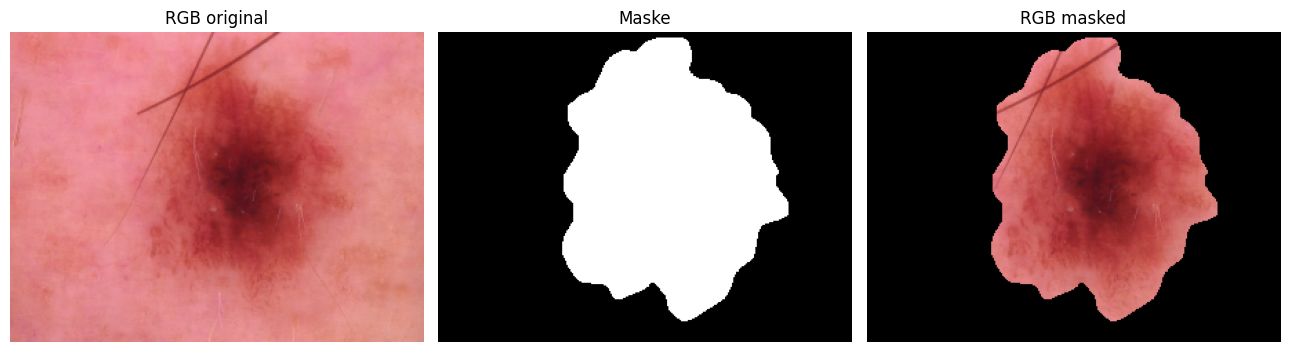

In [3]:
import matplotlib.pyplot as plt
row = df.iloc[0]
original = read_image(row["image_path"])
mask_gray = read_image(row["mask_path"], grayscale=True)
orig_rgb = cv2.cvtColor(cv2.resize(original, SIZE), cv2.COLOR_BGR2RGB)
mask = cv2.resize(mask_gray, SIZE, interpolation=cv2.INTER_NEAREST) > 127
masked_rgb = orig_rgb.copy()
masked_rgb[~mask] = 0
f_original = rgb_color_features(row["image_path"])
f_masked = rgb_color_features(row["image_path"], row["mask_path"])
print("Original özellik:", f_original.shape)
print("Masked özellik:", f_masked.shape)
fig, axes = plt.subplots(1, 3, figsize=(13,4))
axes[0].imshow(orig_rgb);axes[0].set_title("RGB original")
axes[1].imshow(mask, cmap="gray");axes[1].set_title("Maske")
axes[2].imshow(masked_rgb);axes[2].set_title("RGB masked")
for a in axes:a.axis("off")
plt.tight_layout();plt.show()

## 4. 10.015 görüntüyü işle ve diske kaydet
Kaydedilmiş dosyalar varsa varsayılan olarak tekrar hesaplamaz. `FORCE_RECOMPUTE=True` yaparsan yeniden çıkarır. Diziler küçük (yaklaşık 18 MB / dosya).

In [ ]:
import pandas as pd
from numpy.lib.format import open_memmap

original_path = FEATURE_DIR / "X_original_color_300x225.npy"
masked_path = FEATURE_DIR / "X_masked_color_300x225.npy"
label_path = FEATURE_DIR / "y_labels_color_300x225.npy"
id_path = FEATURE_DIR / "image_ids_color_300x225.npy"

FORCE_RECOMPUTE = False
count = len(df)
n_features = len(f_original)

if FORCE_RECOMPUTE or not (original_path.exists() and masked_path.exists() and label_path.exists() and id_path.exists()):
    xo = open_memmap(original_path, mode="w+", dtype="float32", shape=(count, n_features))
    xm = open_memmap(masked_path, mode="w+", dtype="float32", shape=(count, n_features))
    for i, row in df.iterrows():
        xo[i] = rgb_color_features(row["image_path"])

        xm[i] = rgb_color_features(row["image_path"], row["mask_path"])
        if (i + 1) % 1000 == 0:print(f"İşlenen: {i+1}/{count}")
    xo.flush(); xm.flush()
    del xo, xm
    np.save(label_path, np.asarray(df["label"].tolist(),dtype="U10"))
    np.save(id_path, np.asarray(df["image"].tolist(),dtype="U40"))
    print("Renk özellikleri kaydedildi.")
else:
    print("Mevcut renk özellik dosyaları bulundu; tekrar hesaplanmadı.")

İşlenen: 1000/10015
İşlenen: 2000/10015
İşlenen: 3000/10015
İşlenen: 4000/10015
İşlenen: 5000/10015
İşlenen: 6000/10015
İşlenen: 7000/10015
İşlenen: 8000/10015
İşlenen: 9000/10015
İşlenen: 10000/10015
Renk özellikleri kaydedildi.


## 5. Kayıtları doğrula

In [6]:
X_original_color = np.load(original_path, mmap_mode="r")
X_masked_color = np.load(masked_path, mmap_mode="r")
y_saved = np.load(label_path)
ids_saved = np.load(id_path)
assert X_original_color.shape == (len(df), n_features)
assert X_masked_color.shape == X_original_color.shape
assert np.array_equal(ids_saved, df["image"].to_numpy(dtype=str))
assert np.array_equal(y_saved, df["label"].to_numpy(dtype=str))
assert np.isfinite(X_original_color).all() and np.isfinite(X_masked_color).all()
print("Original:", X_original_color.shape, "Masked:", X_masked_color.shape)
print("Yol:", FEATURE_DIR)
print("Doğrulamalar başarılı. Sonraki notebook: 10_color_models.ipynb")

Original: (10015, 439) Masked: (10015, 439)
Yol: C:\Users\Deniz TOZAN\OneDrive - Analythinx Bilişim Hizmetleri Ticaret Anonim Şirketi\WORK\Calismalar\uygulama\Kodlar\Health\outputs\features
Doğrulamalar başarılı. Sonraki notebook: 10_color_models.ipynb


In [ ]:
import winsound

winsound.Beep(300, 3000)
print("Ses testi tamamlandı.")

NameError: name 'image_original' is not defined